# CNN — Patient-Level 1-vs-REST (Weighted Ensemble)

Same pipeline as `Team_09_AlexNet_SVM_Farida_Ali.ipynb` (patient leakage check, stratified 15% patient hold-out,
patient-level 5-fold CV per class-vs-REST, weighted fold ensemble, XAI), but the model is the custom CNN
trained end-to-end instead of a frozen AlexNet + SVM. Runs on Kaggle.

## 0 — Imports & Seeds

In [1]:
import os
import csv
import random
import json
import shutil
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter, defaultdict
from tqdm import tqdm
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models

from sklearn.metrics import confusion_matrix, classification_report, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


## 1 — Configuration

In [2]:
# ── Paths (Kaggle) ───────────────────────────────────────────────────────────
DATA_ROOT  = "/kaggle/input/datasets/faridaali202301940/adnidata/adni_nifti_preprocessed"
OUTPUT_DIR = "/kaggle/working/preprocessed_cnn"
CKPT_DIR   = "/kaggle/working/checkpoints_cnn"
os.makedirs(CKPT_DIR, exist_ok=True)

# ── Hyper-parameters ─────────────────────────────────────────────────────────
IMAGE_SIZE   = 224
N_FOLDS      = 5
BATCH_SIZE   = 32
NUM_EPOCHS   = 40
LR           = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE     = 10
MOMENTUM     = 0.9
NUM_WORKERS  = 2

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

VALID_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

CLASS_NAMES = sorted([
    d for d in os.listdir(DATA_ROOT)
    if os.path.isdir(os.path.join(DATA_ROOT, d))
])
print(f"Classes found: {CLASS_NAMES}")

Classes found: ['AD', 'CN', 'MCI']


## 2 — Build Patient Map & Leakage Check

In [3]:
patient_classes = defaultdict(set)
patient_slices  = defaultdict(list)

for cls in CLASS_NAMES:
    cls_dir = os.path.join(DATA_ROOT, cls)
    if not os.path.isdir(cls_dir):
        print(f"[WARNING] Missing class folder: {cls_dir}")
        continue
    for patient_id in os.listdir(cls_dir):
        patient_dir = os.path.join(cls_dir, patient_id)
        if not os.path.isdir(patient_dir):
            continue
        slices = [
            os.path.join(patient_dir, f)
            for f in os.listdir(patient_dir)
            if os.path.splitext(f)[1].lower() in VALID_EXTS
        ]
        if slices:
            patient_classes[patient_id].add(cls)
            patient_slices[(patient_id, cls)].extend(slices)

print(f"Total unique patients: {len(patient_classes)}")

# ── Leakage check ─────────────────────────────────────────────────────────────
leakage_patients = {
    pid: classes
    for pid, classes in patient_classes.items()
    if len(classes) > 1
}

print(f"\n{'='*55}")
print(f"  LEAKAGE CHECK")
print(f"{'='*55}")
if leakage_patients:
    print(f"  Patients in multiple classes (EXCLUDED): {len(leakage_patients)}")
    for pid, classes in sorted(leakage_patients.items()):
        print(f"    {pid}  ->  {sorted(classes)}")
else:
    print("  No patients in multiple classes. Dataset is clean.")

clean_patients = {
    pid: list(classes)[0]
    for pid, classes in patient_classes.items()
    if pid not in leakage_patients
}
print(f"\n  Patients kept    : {len(clean_patients)}")
print(f"  Patients excluded: {len(leakage_patients)}")

Total unique patients: 320

  LEAKAGE CHECK
  No patients in multiple classes. Dataset is clean.

  Patients kept    : 320
  Patients excluded: 0


## 3 — Hold-Out Test Set (Patient-Level, Stratified 15%)

In [4]:
TEST_RATIO = 0.15

class_patients = defaultdict(list)
for pid, cls in clean_patients.items():
    class_patients[cls].append(pid)

for cls in CLASS_NAMES:
    random.shuffle(class_patients[cls])

test_patients     = []
trainval_patients = []

print(f"{'='*55}")
print(f"  HOLD-OUT TEST SET (stratified by class)")
print(f"{'='*55}")

for cls in CLASS_NAMES:
    pids   = class_patients[cls]
    n_test = max(1, int(len(pids) * TEST_RATIO))
    test_patients.extend(pids[:n_test])
    trainval_patients.extend(pids[n_test:])
    print(f"  {cls}: {len(pids)} total  |  test={n_test}  |  train+val pool={len(pids)-n_test}")

assert not (set(test_patients) & set(trainval_patients)), "Test/trainval overlap!"
print(f"\n  Test patients     : {len(test_patients)}")
print(f"  Train+Val patients: {len(trainval_patients)}")
print(f"  Total             : {len(test_patients)+len(trainval_patients)}")

test_entries = []
for pid in test_patients:
    cls   = clean_patients[pid]
    label = CLASS_NAMES.index(cls)
    for path in patient_slices[(pid, cls)]:
        test_entries.append((path, label, pid))

print(f"  Test slices       : {len(test_entries)}")

  HOLD-OUT TEST SET (stratified by class)
  AD: 54 total  |  test=8  |  train+val pool=46
  CN: 88 total  |  test=13  |  train+val pool=75
  MCI: 178 total  |  test=26  |  train+val pool=152

  Test patients     : 47
  Train+Val patients: 273
  Total             : 320
  Test slices       : 1261


## 4 — Preprocess & Save All Slices to Disk

In [5]:
if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)
os.makedirs(OUTPUT_DIR, exist_ok=True)

all_entries = []
for pid, cls in clean_patients.items():
    label = CLASS_NAMES.index(cls)
    for path in patient_slices[(pid, cls)]:
        all_entries.append((path, label, pid))

fname_counts = {}

def preprocess_and_save(entries, desc="Saving"):
    for path, label, pid in tqdm(entries, desc=desc):
        cls_name = CLASS_NAMES[label]
        out_dir  = os.path.join(OUTPUT_DIR, cls_name)
        os.makedirs(out_dir, exist_ok=True)

        base  = os.path.splitext(os.path.basename(path))[0]
        key   = f"{pid}_{base}"
        fname_counts[key] = fname_counts.get(key, 0) + 1
        suffix   = f"_dup{fname_counts[key]}" if fname_counts[key] > 1 else ""
        out_path = os.path.join(out_dir, f"{key}{suffix}.pt")

        if not os.path.exists(out_path):
            img    = Image.open(path).convert("L")
            img    = img.resize((IMAGE_SIZE, IMAGE_SIZE))
            tensor = transforms.ToTensor()(img)
            tensor = (tensor * 255).byte().repeat(3, 1, 1)
            torch.save(tensor, out_path)

preprocess_and_save(all_entries, desc="Preprocessing all slices")
print(f"Done. {len(all_entries)} slices saved to {OUTPUT_DIR}")

# ── Build pt_lookup from what is actually on disk ─────────────────────────────
pt_lookup = {}
for cls in CLASS_NAMES:
    cls_dir = os.path.join(OUTPUT_DIR, cls)
    if not os.path.isdir(cls_dir):
        continue
    for fname in os.listdir(cls_dir):
        if fname.endswith(".pt"):
            stem = fname[:-3]
            pt_lookup[stem] = os.path.join(cls_dir, fname)

print(f"pt_lookup built: {len(pt_lookup)} entries")

Preprocessing all slices: 100%|██████████| 8512/8512 [08:11<00:00, 17.31it/s]

Done. 8512 slices saved to /kaggle/working/preprocessed_cnn
pt_lookup built: 8512 entries


## 5 — Dataset Class & Augmentation

In [6]:
normalize = transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)

train_augment = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
])

class SliceDataset(Dataset):
    """
    Loads preprocessed .pt tensors for a given list of
    (path, label, patient_id) entries.
    Uses pt_lookup (built from disk) to handle _dupN suffixes correctly.
    """
    def __init__(self, entries, augment=False):
        self.samples = []
        self.augment = augment
        for path, label, pid in entries:
            cls_name = CLASS_NAMES[label]
            base     = os.path.splitext(os.path.basename(path))[0]
            key      = f"{pid}_{base}"

            if key in pt_lookup:
                self.samples.append((pt_lookup[key], label, pid))
            else:
                found = False
                for dup_idx in range(2, 50):
                    dup_key = f"{key}_dup{dup_idx}"
                    if dup_key in pt_lookup:
                        self.samples.append((pt_lookup[dup_key], label, pid))
                        found = True
                        break
                if not found:
                    pass

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        pt_path, label, pid = self.samples[idx]
        tensor = torch.load(pt_path, weights_only=True).float() / 255.0
        if self.augment:
            tensor = train_augment(tensor)
        return normalize(tensor), label, pid

    def get_labels(self): return [s[1] for s in self.samples]

print("SliceDataset class defined.")

SliceDataset class defined.


## 6 — Model Architecture

In [7]:
def build_cnn_model(num_classes):
    model = nn.Sequential(
        nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
        nn.ReLU(inplace=True),
        nn.BatchNorm2d(32),

        nn.Conv2d(32, 32, kernel_size=3, stride=1, padding=1),
        nn.ReLU(inplace=True),
        nn.BatchNorm2d(32),

        nn.MaxPool2d(kernel_size=2, stride=2),

        nn.Conv2d(32, 32, kernel_size=3, stride=1, padding=1),
        nn.ReLU(inplace=True),
        nn.BatchNorm2d(32),

        nn.Conv2d(32, 32, kernel_size=3, stride=1, padding=1),
        nn.ReLU(inplace=True),
        nn.BatchNorm2d(32),

        nn.MaxPool2d(kernel_size=2, stride=2),

        nn.Flatten(),
        nn.Linear(32 * 56 * 56, 128),
        nn.ReLU(inplace=True),
        nn.Dropout(0.2),

        nn.Linear(128, 64),
        nn.ReLU(inplace=True),
        nn.Dropout(0.2),

        nn.Linear(64, num_classes)
    )
    return model

_tmp = build_cnn_model(num_classes=2)
total_params     = sum(p.numel() for p in _tmp.parameters())
trainable_params = sum(p.numel() for p in _tmp.parameters() if p.requires_grad)
del _tmp

print("CNN (trained from scratch, end-to-end) ready.")
print(f"  Total params     : {total_params:,}")
print(f"  Trainable params : {trainable_params:,}")
print(f"  Output           : 2 logits per binary task (REST, positive class)")

CNN (trained from scratch, end-to-end) ready.
  Total params     : 12,882,466
  Trainable params : 12,882,466
  Output           : 2 logits per binary task (REST, positive class)


## 7 — Training Utilities

In [8]:
def run_epoch(loader, model, criterion, optimizer=None, scaler=None, desc=""):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with (torch.enable_grad() if is_train else torch.no_grad()):
        for images, labels, _ in tqdm(loader, desc=desc, leave=False):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast(device_type="cuda"):
                outputs = model(images)
                loss    = criterion(outputs, labels)

            if is_train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            correct    += (outputs.argmax(1) == labels).sum().item()
            total_loss += loss.item() * labels.size(0)
            total      += labels.size(0)

    return total_loss / total, correct / total

def cnn_patient_eval(loader, model):
    """
    Patient-level accuracy using soft slice voting:
      1. Softmax probabilities for every slice.
      2. Average across all slices of a patient.
      3. argmax of averaged probabilities → patient prediction.
    """
    model.eval()
    patient_probs  = defaultdict(list)
    patient_labels = {}
    with torch.no_grad():
        for images, labels, pids in tqdm(loader, desc="Patient-eval", leave=False):
            images = images.to(device, non_blocking=True)
            with torch.amp.autocast(device_type="cuda"):
                logits = model(images)
            probs = torch.softmax(logits.float(), dim=1).cpu().numpy()
            for prob, label, pid in zip(probs, labels.numpy(), pids):
                patient_probs[pid].append(prob)
                patient_labels[pid] = int(label)

    all_true, all_pred = [], []
    for pid, probs_list in patient_probs.items():
        all_true.append(patient_labels[pid])
        all_pred.append(int(np.argmax(np.mean(probs_list, axis=0))))

    acc = np.mean(np.array(all_true) == np.array(all_pred))
    return acc, all_true, all_pred

print("Training utilities defined (run_epoch, cnn_patient_eval).")

Training utilities defined (run_epoch, cnn_patient_eval).


## 8 — K-Fold Cross-Validation (Train+Val Pool)


  AD vs REST  —  5-Fold Cross-Validation  (CNN)

  --- Fold 1/5 ---
  Train slices — AD: 957 | REST: 4851 | Val patients: 56


  Ep 01 | train loss=0.4496 acc=50.7% | val loss=1.6750 acc=18.1%
    ✓ Best val_acc=18.09% — saved.


  Ep 02 | train loss=0.4185 acc=51.3% | val loss=1.6709 acc=19.7%
    ✓ Best val_acc=19.68% — saved.


  Ep 03 | train loss=0.3871 acc=55.3% | val loss=1.1968 acc=31.8%
    ✓ Best val_acc=31.81% — saved.


  Ep 04 | train loss=0.3635 acc=60.2% | val loss=1.4416 acc=35.1%
    ✓ Best val_acc=35.14% — saved.


  Ep 05 | train loss=0.3318 acc=65.0% | val loss=1.7212 acc=29.9%


... (31 outputs left out)

  Ep 37 | train loss=0.0324 acc=97.9% | val loss=1.7793 acc=71.6%


  Ep 38 | train loss=0.0347 acc=97.5% | val loss=1.6987 acc=72.3%


  Ep 39 | train loss=0.0319 acc=98.1% | val loss=1.7499 acc=71.1%


  Ep 40 | train loss=0.0265 acc=98.3% | val loss=1.7938 acc=69.8%


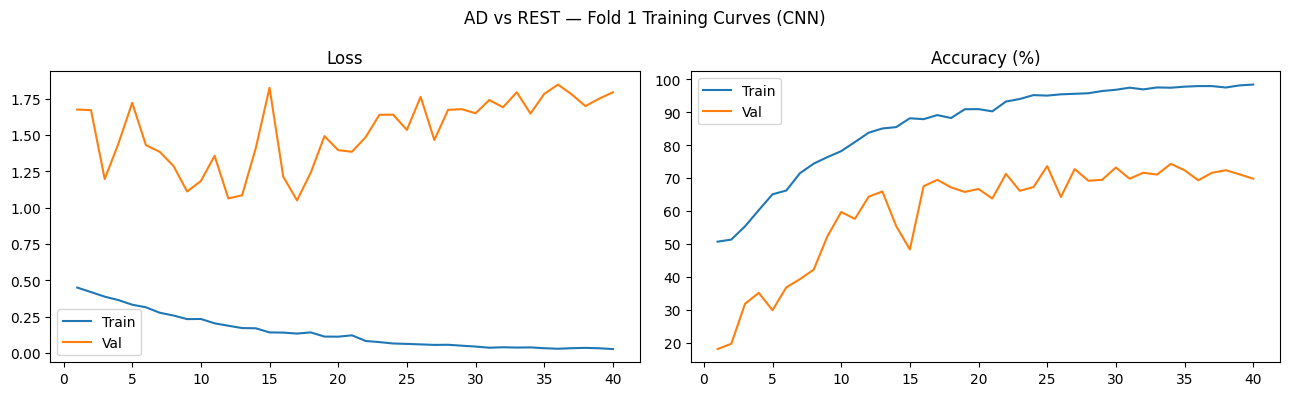

  Fold 1 — Patient-level val acc: 76.79%
  Saved → /kaggle/working/checkpoints_cnn/fold1_AD_vs_rest_cnn.pt

  --- Fold 2/5 ---
  Train slices — AD: 984 | REST: 4801 | Val patients: 55


  Ep 01 | train loss=0.4551 acc=50.7% | val loss=1.3578 acc=16.0%
    ✓ Best val_acc=15.96% — saved.


  Ep 02 | train loss=0.4153 acc=52.3% | val loss=1.1770 acc=16.6%
    ✓ Best val_acc=16.58% — saved.


  Ep 03 | train loss=0.4018 acc=53.3% | val loss=1.6838 acc=18.8%
    ✓ Best val_acc=18.83% — saved.


  Ep 04 | train loss=0.3727 acc=58.3% | val loss=1.0952 acc=37.7%
    ✓ Best val_acc=37.65% — saved.


  Ep 05 | train loss=0.3454 acc=64.9% | val loss=1.0569 acc=53.3%
    ✓ Best val_acc=53.27% — saved.


... (14 outputs left out)

  Ep 20 | train loss=0.0815 acc=93.9% | val loss=1.4613 acc=67.1%


  Ep 21 | train loss=0.0828 acc=94.1% | val loss=1.4624 acc=68.2%


  Ep 22 | train loss=0.0666 acc=95.0% | val loss=1.5041 acc=69.8%


  Ep 23 | train loss=0.0579 acc=95.6% | val loss=1.6824 acc=67.4%
    Early stopping at epoch 23.


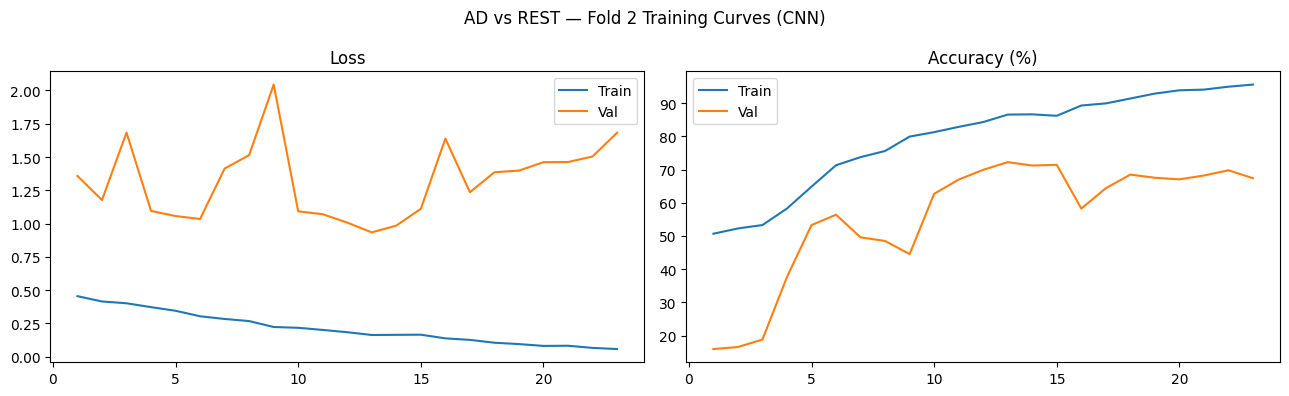

  Fold 2 — Patient-level val acc: 76.36%
  Saved → /kaggle/working/checkpoints_cnn/fold2_AD_vs_rest_cnn.pt

  --- Fold 3/5 ---
  Train slices — AD: 979 | REST: 4824 | Val patients: 54


  Ep 01 | train loss=0.4602 acc=50.4% | val loss=1.4067 acc=16.5%
    ✓ Best val_acc=16.51% — saved.


  Ep 02 | train loss=0.4021 acc=54.9% | val loss=1.5890 acc=21.7%
    ✓ Best val_acc=21.69% — saved.


  Ep 03 | train loss=0.3741 acc=60.6% | val loss=1.0600 acc=40.5%
    ✓ Best val_acc=40.47% — saved.


  Ep 04 | train loss=0.3336 acc=67.2% | val loss=1.0573 acc=49.0%
    ✓ Best val_acc=48.96% — saved.


  Ep 05 | train loss=0.3032 acc=70.2% | val loss=1.2078 acc=46.5%


... (26 outputs left out)

  Ep 32 | train loss=0.0543 acc=96.2% | val loss=1.2383 acc=78.7%


  Ep 33 | train loss=0.0485 acc=96.5% | val loss=1.3203 acc=78.9%


  Ep 34 | train loss=0.0542 acc=95.7% | val loss=1.2474 acc=79.4%


  Ep 35 | train loss=0.0468 acc=96.5% | val loss=1.2198 acc=80.2%
    Early stopping at epoch 35.


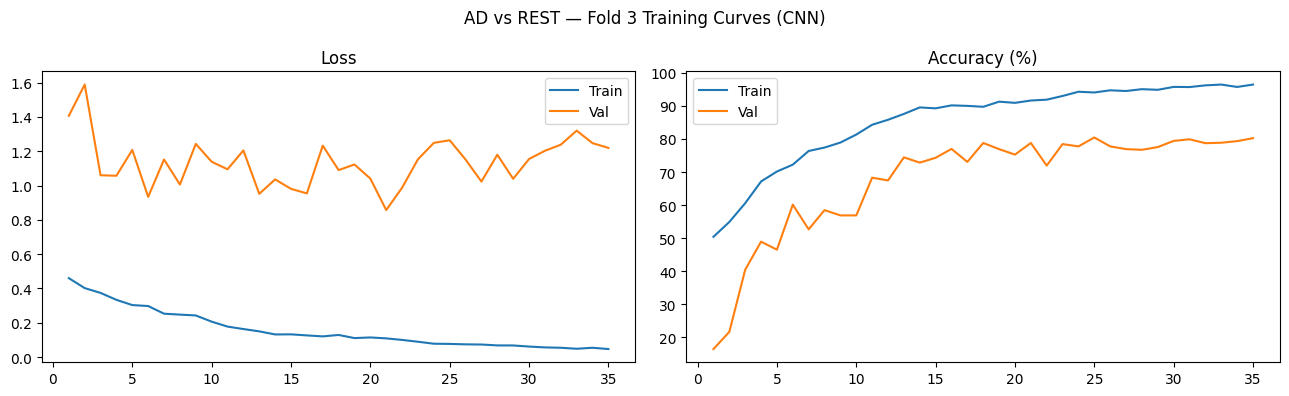

  Fold 3 — Patient-level val acc: 83.33%
  Saved → /kaggle/working/checkpoints_cnn/fold3_AD_vs_rest_cnn.pt

  --- Fold 4/5 ---
  Train slices — AD: 975 | REST: 4832 | Val patients: 54


  Ep 01 | train loss=0.4604 acc=50.4% | val loss=1.4492 acc=16.8%
    ✓ Best val_acc=16.83% — saved.


  Ep 02 | train loss=0.4218 acc=50.9% | val loss=1.7406 acc=16.8%


  Ep 03 | train loss=0.4074 acc=53.6% | val loss=0.9703 acc=43.7%
    ✓ Best val_acc=43.70% — saved.


  Ep 04 | train loss=0.3618 acc=60.6% | val loss=1.2311 acc=35.0%


  Ep 05 | train loss=0.3436 acc=64.7% | val loss=0.9223 acc=50.3%
    ✓ Best val_acc=50.35% — saved.


... (31 outputs left out)

  Ep 37 | train loss=0.0753 acc=94.5% | val loss=1.0092 acc=71.3%


  Ep 38 | train loss=0.0730 acc=94.6% | val loss=1.0487 acc=70.9%


  Ep 39 | train loss=0.0686 acc=94.5% | val loss=1.1167 acc=69.7%


  Ep 40 | train loss=0.0681 acc=95.0% | val loss=1.0917 acc=70.2%


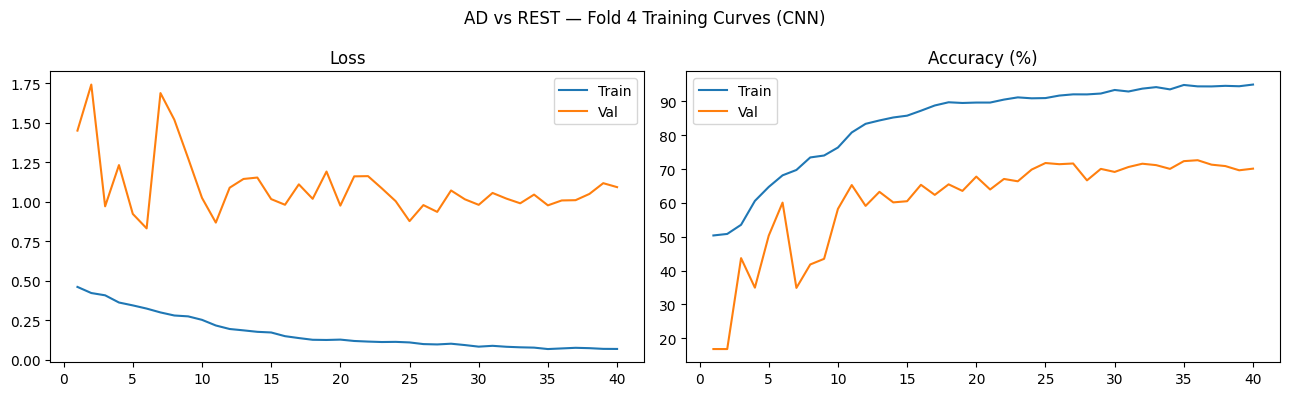

  Fold 4 — Patient-level val acc: 75.93%
  Saved → /kaggle/working/checkpoints_cnn/fold4_AD_vs_rest_cnn.pt

  --- Fold 5/5 ---
  Train slices — AD: 977 | REST: 4824 | Val patients: 54


  Ep 01 | train loss=0.4655 acc=50.3% | val loss=1.2021 acc=16.6%
    ✓ Best val_acc=16.62% — saved.


  Ep 02 | train loss=0.4367 acc=49.6% | val loss=1.0315 acc=20.6%
    ✓ Best val_acc=20.55% — saved.


  Ep 03 | train loss=0.3948 acc=54.8% | val loss=1.1859 acc=26.1%
    ✓ Best val_acc=26.07% — saved.


  Ep 04 | train loss=0.3604 acc=61.9% | val loss=0.9864 acc=45.0%
    ✓ Best val_acc=44.97% — saved.


  Ep 05 | train loss=0.3499 acc=63.8% | val loss=1.0580 acc=44.4%


... (30 outputs left out)

  Ep 36 | train loss=0.0624 acc=95.3% | val loss=1.0428 acc=78.8%


  Ep 37 | train loss=0.0519 acc=96.2% | val loss=1.1198 acc=82.8%


  Ep 38 | train loss=0.0522 acc=96.2% | val loss=1.0756 acc=82.0%


  Ep 39 | train loss=0.0507 acc=96.6% | val loss=1.0998 acc=81.9%
    Early stopping at epoch 39.


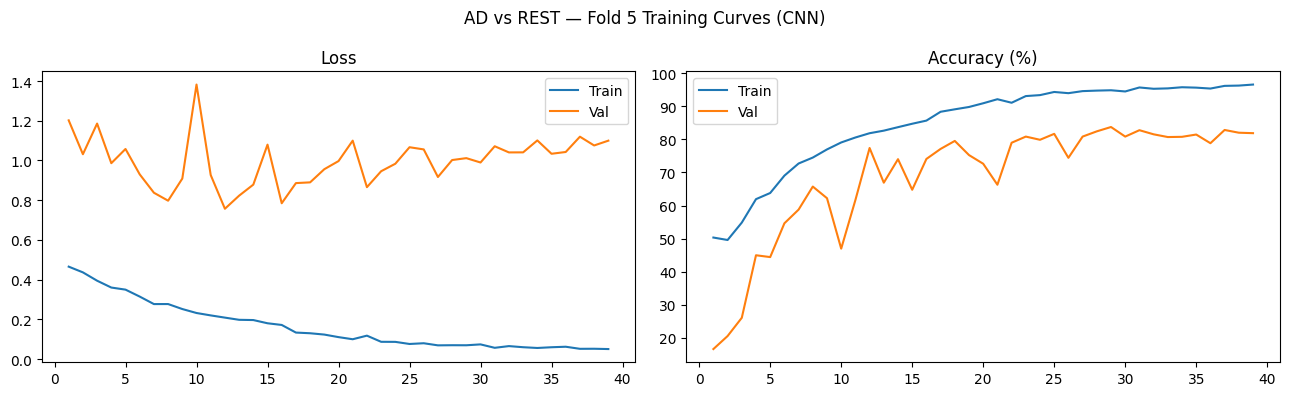

  Fold 5 — Patient-level val acc: 83.33%
  Saved → /kaggle/working/checkpoints_cnn/fold5_AD_vs_rest_cnn.pt

  AD vs REST — 5-Fold CV Patient Acc: 79.15% ± 3.43%

  CN vs REST  —  5-Fold Cross-Validation  (CNN)

  --- Fold 1/5 ---
  Train slices — CN: 1604 | REST: 4204 | Val patients: 56


  Ep 01 | train loss=0.5939 acc=50.5% | val loss=0.8484 acc=30.1%
    ✓ Best val_acc=30.15% — saved.


  Ep 02 | train loss=0.5475 acc=51.4% | val loss=0.9379 acc=27.4%


  Ep 03 | train loss=0.5151 acc=56.2% | val loss=0.9898 acc=36.8%
    ✓ Best val_acc=36.80% — saved.


  Ep 04 | train loss=0.5045 acc=59.5% | val loss=1.2417 acc=33.0%


  Ep 05 | train loss=0.4692 acc=66.1% | val loss=1.1523 acc=46.2%
    ✓ Best val_acc=46.22% — saved.


... (13 outputs left out)

  Ep 19 | train loss=0.2060 acc=88.6% | val loss=1.4281 acc=63.4%


  Ep 20 | train loss=0.1884 acc=89.8% | val loss=1.5149 acc=64.1%


  Ep 21 | train loss=0.1781 acc=90.7% | val loss=1.3046 acc=65.8%


  Ep 22 | train loss=0.1661 acc=91.1% | val loss=1.3171 acc=67.6%
    Early stopping at epoch 22.


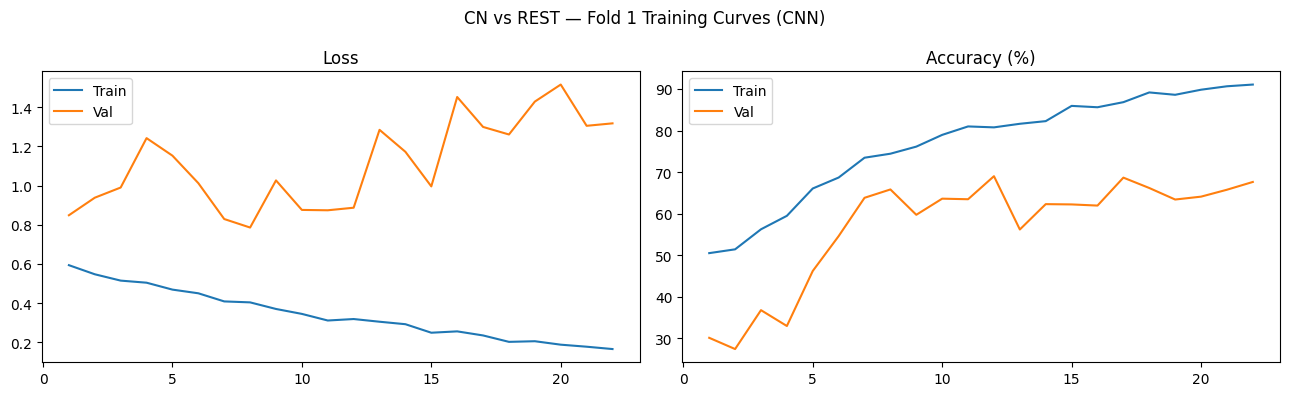

  Fold 1 — Patient-level val acc: 69.64%
  Saved → /kaggle/working/checkpoints_cnn/fold1_CN_vs_rest_cnn.pt

  --- Fold 2/5 ---
  Train slices — CN: 1593 | REST: 4192 | Val patients: 55


  Ep 01 | train loss=0.5881 acc=50.4% | val loss=1.0105 acc=27.4%
    ✓ Best val_acc=27.42% — saved.


  Ep 02 | train loss=0.5621 acc=51.7% | val loss=0.7660 acc=46.0%
    ✓ Best val_acc=46.04% — saved.


  Ep 03 | train loss=0.5415 acc=55.7% | val loss=0.8264 acc=47.1%
    ✓ Best val_acc=47.07% — saved.


  Ep 04 | train loss=0.5150 acc=60.8% | val loss=0.7964 acc=56.4%
    ✓ Best val_acc=56.41% — saved.


  Ep 05 | train loss=0.4897 acc=63.5% | val loss=0.7369 acc=59.6%
    ✓ Best val_acc=59.62% — saved.


... (12 outputs left out)

  Ep 18 | train loss=0.2139 acc=87.8% | val loss=1.0992 acc=68.2%


  Ep 19 | train loss=0.2148 acc=88.0% | val loss=1.2239 acc=67.8%


  Ep 20 | train loss=0.1933 acc=89.0% | val loss=1.2927 acc=66.8%


  Ep 21 | train loss=0.1752 acc=89.7% | val loss=1.3390 acc=62.3%
    Early stopping at epoch 21.


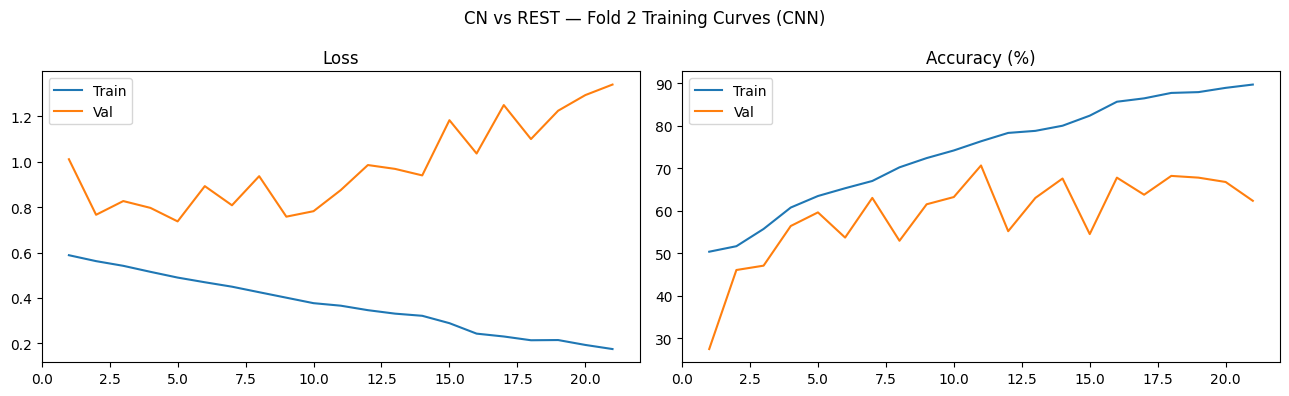

  Fold 2 — Patient-level val acc: 70.91%
  Saved → /kaggle/working/checkpoints_cnn/fold2_CN_vs_rest_cnn.pt

  --- Fold 3/5 ---
  Train slices — CN: 1589 | REST: 4214 | Val patients: 54


  Ep 01 | train loss=0.5898 acc=50.2% | val loss=0.9813 acc=27.8%
    ✓ Best val_acc=27.83% — saved.


  Ep 02 | train loss=0.5649 acc=51.1% | val loss=0.8312 acc=32.3%
    ✓ Best val_acc=32.25% — saved.


  Ep 03 | train loss=0.5344 acc=54.9% | val loss=0.7975 acc=43.8%
    ✓ Best val_acc=43.78% — saved.


  Ep 04 | train loss=0.5248 acc=59.2% | val loss=1.0893 acc=34.4%


  Ep 05 | train loss=0.5012 acc=62.3% | val loss=0.8260 acc=51.0%
    ✓ Best val_acc=51.04% — saved.


... (31 outputs left out)

  Ep 37 | train loss=0.1027 acc=94.9% | val loss=1.1229 acc=70.6%


  Ep 38 | train loss=0.1165 acc=94.2% | val loss=1.1380 acc=69.1%


  Ep 39 | train loss=0.1111 acc=94.2% | val loss=0.9927 acc=71.3%


  Ep 40 | train loss=0.1211 acc=93.6% | val loss=1.1133 acc=68.7%


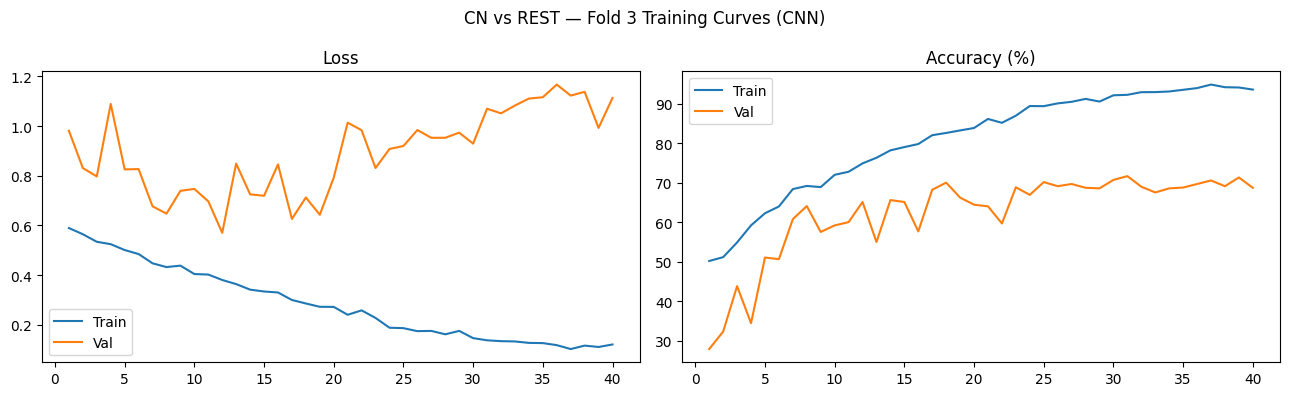

  Fold 3 — Patient-level val acc: 74.07%
  Saved → /kaggle/working/checkpoints_cnn/fold3_CN_vs_rest_cnn.pt

  --- Fold 4/5 ---
  Train slices — CN: 1591 | REST: 4216 | Val patients: 54


  Ep 01 | train loss=0.5930 acc=49.3% | val loss=0.9010 acc=27.8%
    ✓ Best val_acc=27.77% — saved.


  Ep 02 | train loss=0.5543 acc=52.2% | val loss=0.9392 acc=33.4%
    ✓ Best val_acc=33.45% — saved.


  Ep 03 | train loss=0.5321 acc=57.6% | val loss=0.7830 acc=50.5%
    ✓ Best val_acc=50.48% — saved.


  Ep 04 | train loss=0.4918 acc=64.4% | val loss=0.7319 acc=59.0%
    ✓ Best val_acc=59.00% — saved.


  Ep 05 | train loss=0.4668 acc=67.0% | val loss=0.7622 acc=60.0%
    ✓ Best val_acc=59.97% — saved.


... (31 outputs left out)

  Ep 37 | train loss=0.0964 acc=95.0% | val loss=2.0050 acc=68.4%
    ✓ Best val_acc=68.35% — saved.


  Ep 38 | train loss=0.1013 acc=95.2% | val loss=1.8460 acc=67.7%


  Ep 39 | train loss=0.1009 acc=94.9% | val loss=2.0633 acc=67.3%


  Ep 40 | train loss=0.1037 acc=95.0% | val loss=2.1221 acc=67.5%


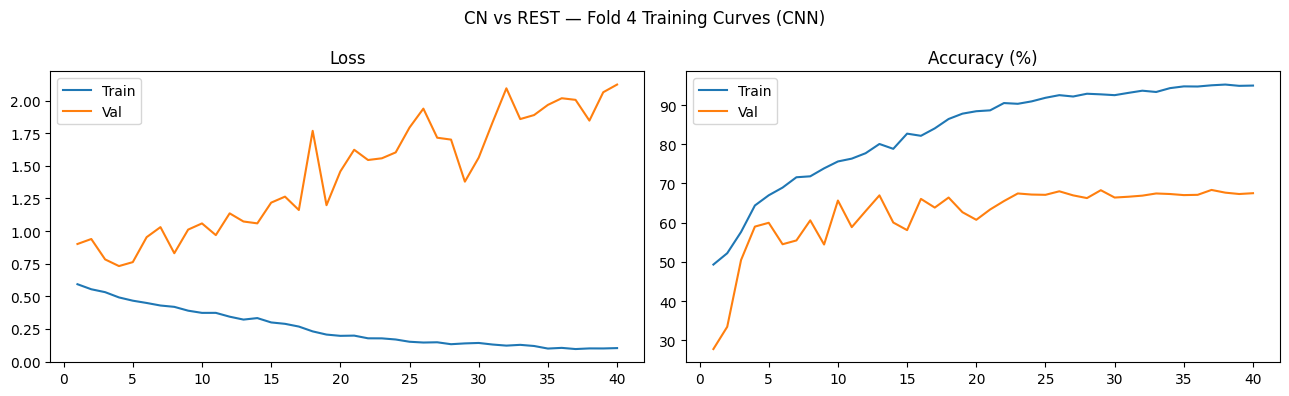

  Fold 4 — Patient-level val acc: 70.37%
  Saved → /kaggle/working/checkpoints_cnn/fold4_CN_vs_rest_cnn.pt

  --- Fold 5/5 ---
  Train slices — CN: 1591 | REST: 4210 | Val patients: 54


  Ep 01 | train loss=0.5994 acc=50.1% | val loss=0.9746 acc=27.7%
    ✓ Best val_acc=27.66% — saved.


  Ep 02 | train loss=0.5619 acc=51.8% | val loss=1.1806 acc=30.1%
    ✓ Best val_acc=30.07% — saved.


  Ep 03 | train loss=0.5461 acc=54.1% | val loss=0.9369 acc=28.8%


  Ep 04 | train loss=0.5066 acc=59.7% | val loss=1.2352 acc=29.9%


  Ep 05 | train loss=0.4992 acc=62.6% | val loss=0.9348 acc=42.3%
    ✓ Best val_acc=42.34% — saved.


... (31 outputs left out)

  Ep 37 | train loss=0.1191 acc=93.6% | val loss=1.7819 acc=70.5%
    ✓ Best val_acc=70.48% — saved.


  Ep 38 | train loss=0.1100 acc=94.2% | val loss=1.8679 acc=66.6%


  Ep 39 | train loss=0.0990 acc=95.3% | val loss=1.8633 acc=69.7%


  Ep 40 | train loss=0.1072 acc=94.3% | val loss=1.9752 acc=66.4%


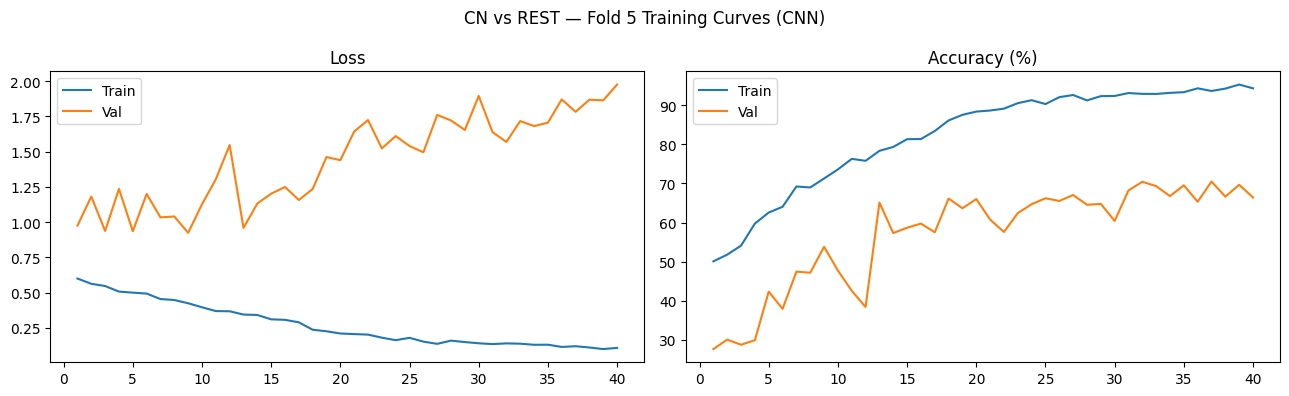

  Fold 5 — Patient-level val acc: 72.22%
  Saved → /kaggle/working/checkpoints_cnn/fold5_CN_vs_rest_cnn.pt

  CN vs REST — 5-Fold CV Patient Acc: 71.44% ± 1.56%

  MCI vs REST  —  5-Fold Cross-Validation  (CNN)

  --- Fold 1/5 ---
  Train slices — MCI: 3247 | REST: 2561 | Val patients: 56


  Ep 01 | train loss=0.6961 acc=50.1% | val loss=0.7315 acc=39.4%
    ✓ Best val_acc=39.43% — saved.


  Ep 02 | train loss=0.6799 acc=53.1% | val loss=0.7568 acc=45.4%
    ✓ Best val_acc=45.39% — saved.


  Ep 03 | train loss=0.6722 acc=53.3% | val loss=0.7228 acc=42.5%


  Ep 04 | train loss=0.6627 acc=57.0% | val loss=0.7352 acc=44.3%


  Ep 05 | train loss=0.6403 acc=61.9% | val loss=0.7941 acc=44.7%


... (10 outputs left out)

  Ep 16 | train loss=0.4337 acc=79.1% | val loss=1.2914 acc=50.0%


  Ep 17 | train loss=0.4061 acc=80.4% | val loss=1.5262 acc=45.7%


  Ep 18 | train loss=0.3679 acc=82.9% | val loss=1.5943 acc=47.4%


  Ep 19 | train loss=0.3533 acc=84.1% | val loss=1.5220 acc=47.0%
    Early stopping at epoch 19.


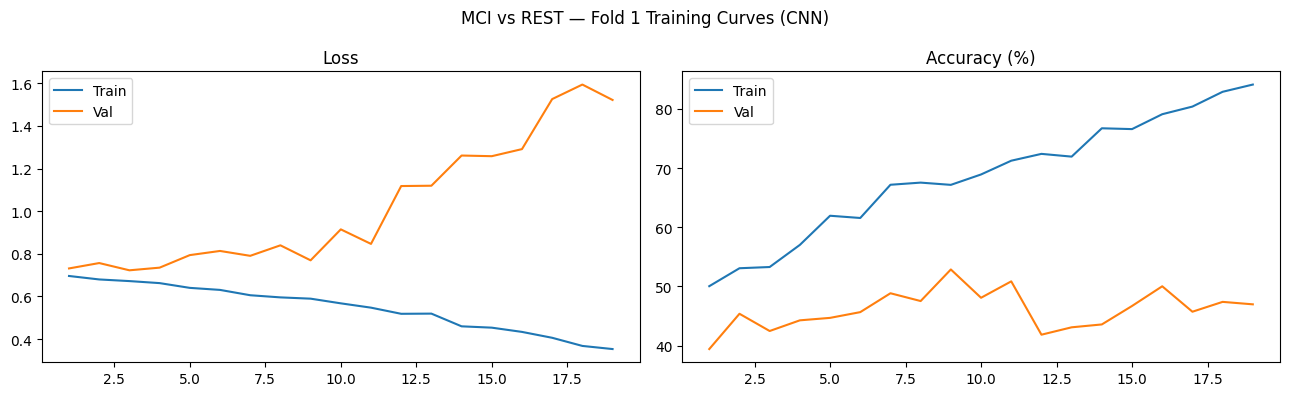

  Fold 1 — Patient-level val acc: 50.00%
  Saved → /kaggle/working/checkpoints_cnn/fold1_MCI_vs_rest_cnn.pt

  --- Fold 2/5 ---
  Train slices — MCI: 3208 | REST: 2577 | Val patients: 55


  Ep 01 | train loss=0.6997 acc=52.1% | val loss=0.7036 acc=54.6%
    ✓ Best val_acc=54.64% — saved.


  Ep 02 | train loss=0.6878 acc=52.8% | val loss=0.7115 acc=51.2%


  Ep 03 | train loss=0.6725 acc=55.2% | val loss=0.7197 acc=48.6%


  Ep 04 | train loss=0.6612 acc=56.6% | val loss=0.7223 acc=52.9%


  Ep 05 | train loss=0.6414 acc=61.0% | val loss=0.8399 acc=48.0%


... (2 outputs left out)

  Ep 08 | train loss=0.5895 acc=67.3% | val loss=0.8954 acc=50.9%


  Ep 09 | train loss=0.5690 acc=69.3% | val loss=0.9204 acc=52.5%


  Ep 10 | train loss=0.5551 acc=70.4% | val loss=0.9261 acc=52.3%


  Ep 11 | train loss=0.5378 acc=72.8% | val loss=0.9213 acc=54.5%
    Early stopping at epoch 11.


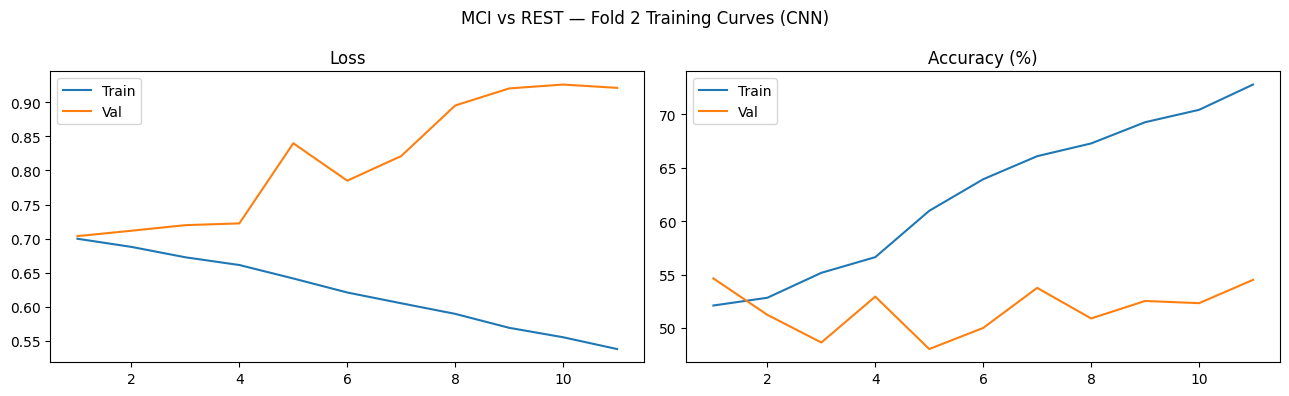

  Fold 2 — Patient-level val acc: 56.36%
  Saved → /kaggle/working/checkpoints_cnn/fold2_MCI_vs_rest_cnn.pt

  --- Fold 3/5 ---
  Train slices — MCI: 3235 | REST: 2568 | Val patients: 54


  Ep 01 | train loss=0.6966 acc=50.4% | val loss=0.7135 acc=45.7%
    ✓ Best val_acc=45.72% — saved.


  Ep 02 | train loss=0.6852 acc=51.3% | val loss=0.7382 acc=45.4%


  Ep 03 | train loss=0.6810 acc=53.4% | val loss=0.7317 acc=45.9%
    ✓ Best val_acc=45.93% — saved.


  Ep 04 | train loss=0.6715 acc=55.6% | val loss=0.7272 acc=42.5%


  Ep 05 | train loss=0.6624 acc=58.5% | val loss=0.7421 acc=43.8%


... (24 outputs left out)

  Ep 30 | train loss=0.3411 acc=84.8% | val loss=1.3262 acc=52.0%


  Ep 31 | train loss=0.3192 acc=86.0% | val loss=1.4172 acc=51.5%


  Ep 32 | train loss=0.3160 acc=86.2% | val loss=1.3284 acc=53.3%


  Ep 33 | train loss=0.2850 acc=87.3% | val loss=1.3640 acc=53.0%
    Early stopping at epoch 33.


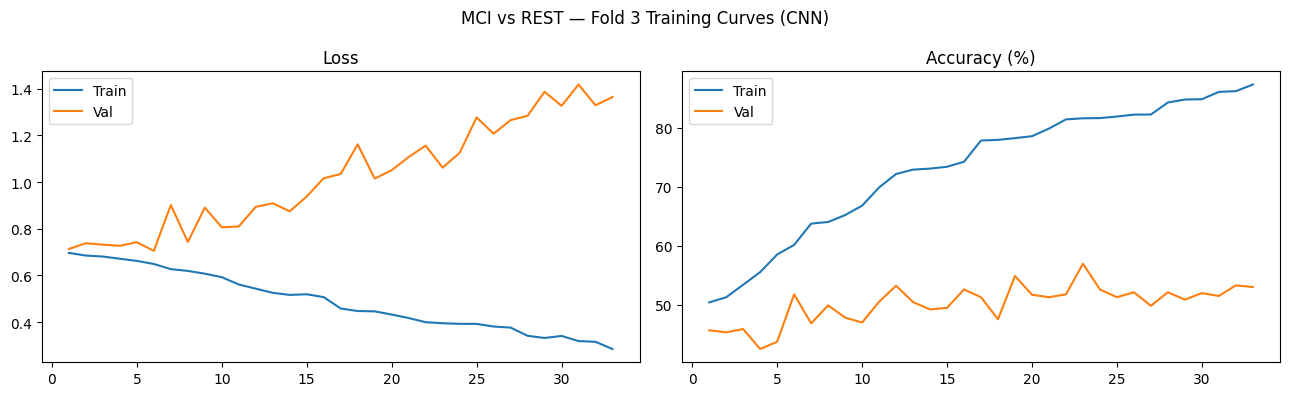

  Fold 3 — Patient-level val acc: 55.56%
  Saved → /kaggle/working/checkpoints_cnn/fold3_MCI_vs_rest_cnn.pt

  --- Fold 4/5 ---
  Train slices — MCI: 3241 | REST: 2566 | Val patients: 54


  Ep 01 | train loss=0.7009 acc=49.8% | val loss=0.7336 acc=44.7%
    ✓ Best val_acc=44.74% — saved.


  Ep 02 | train loss=0.6819 acc=53.1% | val loss=0.7227 acc=46.5%
    ✓ Best val_acc=46.47% — saved.


  Ep 03 | train loss=0.6690 acc=56.1% | val loss=0.7176 acc=51.0%
    ✓ Best val_acc=51.04% — saved.


  Ep 04 | train loss=0.6622 acc=57.9% | val loss=0.7223 acc=53.8%
    ✓ Best val_acc=53.81% — saved.


  Ep 05 | train loss=0.6485 acc=60.6% | val loss=0.8110 acc=40.7%


... (17 outputs left out)

  Ep 23 | train loss=0.3948 acc=81.1% | val loss=1.1702 acc=55.0%


  Ep 24 | train loss=0.3825 acc=82.1% | val loss=1.3770 acc=51.2%


  Ep 25 | train loss=0.3692 acc=83.1% | val loss=1.3599 acc=52.8%


  Ep 26 | train loss=0.3523 acc=84.2% | val loss=1.3592 acc=51.4%
    Early stopping at epoch 26.


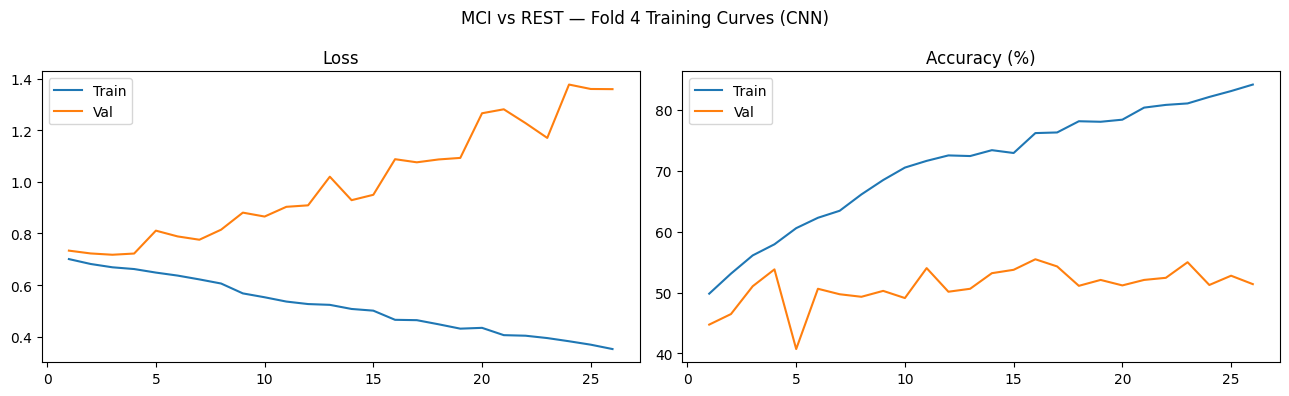

  Fold 4 — Patient-level val acc: 59.26%
  Saved → /kaggle/working/checkpoints_cnn/fold4_MCI_vs_rest_cnn.pt

  --- Fold 5/5 ---
  Train slices — MCI: 3233 | REST: 2568 | Val patients: 54


  Ep 01 | train loss=0.6926 acc=51.2% | val loss=0.6986 acc=50.3%
    ✓ Best val_acc=50.34% — saved.


  Ep 02 | train loss=0.6823 acc=52.2% | val loss=0.7623 acc=43.4%


  Ep 03 | train loss=0.6718 acc=55.9% | val loss=0.7723 acc=43.5%


  Ep 04 | train loss=0.6653 acc=57.9% | val loss=0.8055 acc=37.6%


  Ep 05 | train loss=0.6540 acc=60.4% | val loss=0.7619 acc=42.0%


... (7 outputs left out)

  Ep 13 | train loss=0.5466 acc=71.6% | val loss=0.8320 acc=56.2%


  Ep 14 | train loss=0.5430 acc=72.0% | val loss=0.8617 acc=47.7%


  Ep 15 | train loss=0.5174 acc=74.1% | val loss=0.8993 acc=50.2%


  Ep 16 | train loss=0.5155 acc=73.9% | val loss=0.8419 acc=55.8%
    Early stopping at epoch 16.


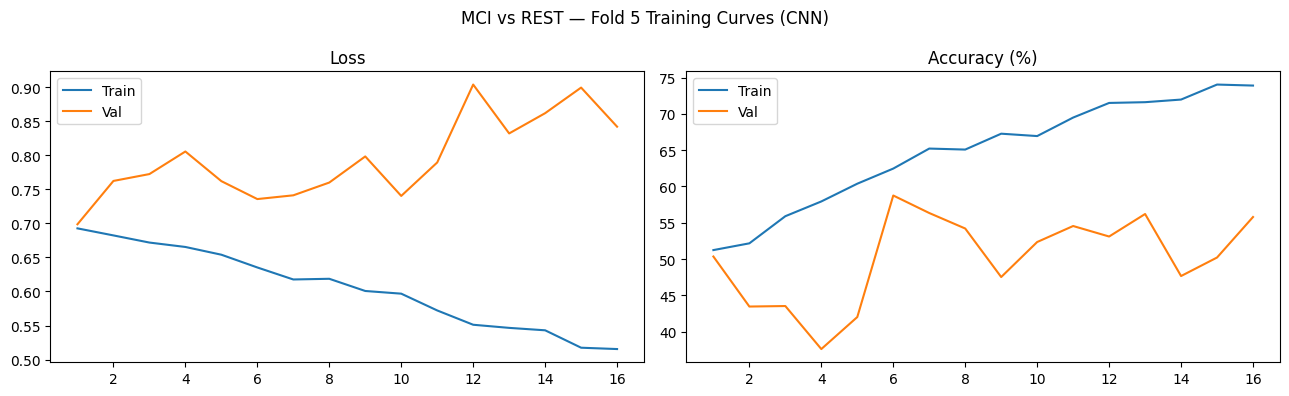

  Fold 5 — Patient-level val acc: 53.70%
  Saved → /kaggle/working/checkpoints_cnn/fold5_MCI_vs_rest_cnn.pt

  MCI vs REST — 5-Fold CV Patient Acc: 54.98% ± 3.07%


All folds done.


In [9]:
import torch._dynamo
torch._dynamo.config.suppress_errors = True

trainval_by_class = defaultdict(list)
for pid in trainval_patients:
    trainval_by_class[clean_patients[pid]].append(pid)

for cls in CLASS_NAMES:
    random.shuffle(trainval_by_class[cls])

fold_results    = {cls: [] for cls in CLASS_NAMES}
all_fold_ckpts  = {cls: [] for cls in CLASS_NAMES}
all_fold_models = {cls: [] for cls in CLASS_NAMES}

for pos_class_idx, pos_name in enumerate(CLASS_NAMES):
    print(f"\n{'='*65}")
    print(f"  {pos_name} vs REST  —  {N_FOLDS}-Fold Cross-Validation  (CNN)")
    print(f"{'='*65}")

    binary_names = ["REST", pos_name]

    class_folds = {}
    for cls in CLASS_NAMES:
        pids  = trainval_by_class[cls]
        folds = [pids[i::N_FOLDS] for i in range(N_FOLDS)]
        class_folds[cls] = folds

    for fold_idx in range(N_FOLDS):
        print(f"\n  --- Fold {fold_idx+1}/{N_FOLDS} ---")

        val_pids_fold = []
        for cls in CLASS_NAMES:
            val_pids_fold.extend(class_folds[cls][fold_idx])

        train_pids_fold = []
        for cls in CLASS_NAMES:
            for k, chunk in enumerate(class_folds[cls]):
                if k != fold_idx:
                    train_pids_fold.extend(chunk)

        def expand(pids):
            out = []
            for pid in pids:
                cls   = clean_patients[pid]
                label = CLASS_NAMES.index(cls)
                for path in patient_slices[(pid, cls)]:
                    out.append((path, label, pid))
            return out

        train_entries_fold = expand(train_pids_fold)
        val_entries_fold   = expand(val_pids_fold)

        def binarize(entries):
            return [(p, 1 if l == pos_class_idx else 0, pid)
                    for p, l, pid in entries]

        train_bin = binarize(train_entries_fold)
        val_bin   = binarize(val_entries_fold)

        train_ds = SliceDataset(train_bin, augment=True)
        val_ds   = SliceDataset(val_bin,   augment=False)

        pos_count = sum(1 for _, l, _ in train_bin if l == 1)
        neg_count = len(train_bin) - pos_count
        print(f"  Train slices — {pos_name}: {pos_count} | REST: {neg_count} | "
              f"Val patients: {len(val_pids_fold)}")

        if len(train_ds) == 0:
            raise RuntimeError(
                f"Fold {fold_idx+1} ({pos_name}): train_ds is empty! "
                f"Re-run Step 4 to rebuild the preprocessed cache."
            )

        train_labels_list = train_ds.get_labels()
        cls_counts = Counter(train_labels_list)
        weights    = [1.0 / cls_counts[l] for l in train_labels_list]
        sampler    = WeightedRandomSampler(weights, len(weights), replacement=True)

        train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler,
                                  num_workers=NUM_WORKERS, pin_memory=True)
        val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                                  num_workers=NUM_WORKERS, pin_memory=True)

        # ── Build & train CNN ──────────────────────────────────────────────
        model = build_cnn_model(num_classes=2).to(device)

        total_train   = pos_count + neg_count
        class_weights = torch.tensor(
            [total_train / (2.0 * neg_count), total_train / (2.0 * pos_count)],
            dtype=torch.float32, device=device)
        criterion = nn.CrossEntropyLoss(weight=class_weights)
        optimizer = optim.SGD(model.parameters(), lr=LR, momentum=MOMENTUM,
                              weight_decay=WEIGHT_DECAY)
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max",
                                                         factor=0.5, patience=3)
        scaler = torch.amp.GradScaler()

        ckpt_path = os.path.join(CKPT_DIR, f"fold{fold_idx+1}_{pos_name}_vs_rest_cnn.pt")
        best_val_acc, patience_ctr = 0.0, 0
        history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

        for epoch in range(1, NUM_EPOCHS + 1):
            tr_loss, tr_acc = run_epoch(train_loader, model, criterion, optimizer, scaler,
                                        desc=f"Ep{epoch}/{NUM_EPOCHS} [train]")
            vl_loss, vl_acc = run_epoch(val_loader, model, criterion,
                                        desc=f"Ep{epoch}/{NUM_EPOCHS} [val]")
            for k, v in zip(history, (tr_loss, tr_acc, vl_loss, vl_acc)):
                history[k].append(v)
            scheduler.step(vl_acc)

            print(f"  Ep {epoch:02d} | train loss={tr_loss:.4f} acc={tr_acc*100:.1f}% | "
                  f"val loss={vl_loss:.4f} acc={vl_acc*100:.1f}%")

            if vl_acc > best_val_acc:
                best_val_acc = vl_acc
                torch.save(model.state_dict(), ckpt_path)
                patience_ctr = 0
                print(f"    ✓ Best val_acc={best_val_acc*100:.2f}% — saved.")
            else:
                patience_ctr += 1
                if patience_ctr >= PATIENCE:
                    print(f"    Early stopping at epoch {epoch}.")
                    break

        # Learning curves
        ep_range = range(1, len(history["train_loss"]) + 1)
        fig, axes = plt.subplots(1, 2, figsize=(13, 4))
        fig.suptitle(f"{pos_name} vs REST — Fold {fold_idx+1} Training Curves (CNN)")
        axes[0].plot(ep_range, history["train_loss"], label="Train")
        axes[0].plot(ep_range, history["val_loss"],   label="Val")
        axes[0].set_title("Loss"); axes[0].legend()
        axes[1].plot(ep_range, [a*100 for a in history["train_acc"]], label="Train")
        axes[1].plot(ep_range, [a*100 for a in history["val_acc"]],   label="Val")
        axes[1].set_title("Accuracy (%)"); axes[1].legend()
        plt.tight_layout()
        plt.savefig(os.path.join(CKPT_DIR, f"curves_fold{fold_idx+1}_{pos_name}_vs_rest.png"), dpi=120)
        plt.show()

        # Best weights → patient-level val accuracy
        model.load_state_dict(torch.load(ckpt_path, map_location=device))
        pat_acc, _, _ = cnn_patient_eval(val_loader, model)
        print(f"  Fold {fold_idx+1} — Patient-level val acc: {pat_acc*100:.2f}%")
        print(f"  Saved → {ckpt_path}")

        fold_results[pos_name].append(pat_acc)
        all_fold_ckpts[pos_name].append(ckpt_path)
        model.to("cpu"); model.eval()
        all_fold_models[pos_name].append(model)

        del optimizer, scaler, train_ds, val_ds
        torch.cuda.empty_cache()

    mean_acc = np.mean(fold_results[pos_name]) * 100
    std_acc  = np.std(fold_results[pos_name])  * 100
    print(f"\n  {pos_name} vs REST — {N_FOLDS}-Fold CV Patient Acc: "
          f"{mean_acc:.2f}% ± {std_acc:.2f}%")

print("\n\nAll folds done.")

## 9 — Weighted Ensemble Evaluation on Hold-Out Test Set

  WEIGHTED ENSEMBLE — HOLD-OUT TEST EVALUATION (Patient-Level)
  Model: CNN (trained from scratch)

  AD vs REST
    Fold 1: val_acc=76.79%  weight=0.1940
    Fold 2: val_acc=76.36%  weight=0.1930
    Fold 3: val_acc=83.33%  weight=0.2106
    Fold 4: val_acc=75.93%  weight=0.1919
    Fold 5: val_acc=83.33%  weight=0.2106



  Weighted Ensemble Test Acc (AD vs REST): 82.98%  [47 patients]
              precision    recall  f1-score   support

        REST       0.88      0.92      0.90        39
          AD       0.50      0.38      0.43         8

    accuracy                           0.83        47
   macro avg       0.69      0.65      0.66        47
weighted avg       0.81      0.83      0.82        47



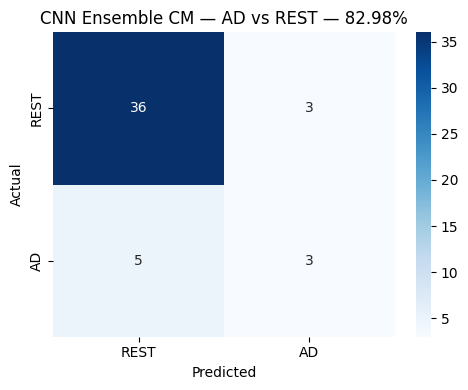


  CN vs REST
    Fold 1: val_acc=69.64%  weight=0.1950
    Fold 2: val_acc=70.91%  weight=0.1985
    Fold 3: val_acc=74.07%  weight=0.2074
    Fold 4: val_acc=70.37%  weight=0.1970
    Fold 5: val_acc=72.22%  weight=0.2022



  Weighted Ensemble Test Acc (CN vs REST): 76.60%  [47 patients]
              precision    recall  f1-score   support

        REST       0.79      0.91      0.85        34
          CN       0.62      0.38      0.48        13

    accuracy                           0.77        47
   macro avg       0.71      0.65      0.66        47
weighted avg       0.75      0.77      0.75        47



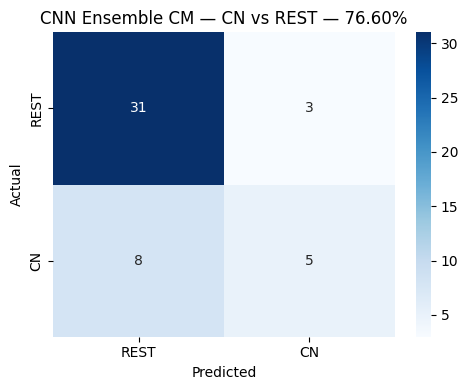


  MCI vs REST
    Fold 1: val_acc=50.00%  weight=0.1819
    Fold 2: val_acc=56.36%  weight=0.2050
    Fold 3: val_acc=55.56%  weight=0.2021
    Fold 4: val_acc=59.26%  weight=0.2156
    Fold 5: val_acc=53.70%  weight=0.1954



  Weighted Ensemble Test Acc (MCI vs REST): 53.19%  [47 patients]
              precision    recall  f1-score   support

        REST       0.47      0.38      0.42        21
         MCI       0.57      0.65      0.61        26

    accuracy                           0.53        47
   macro avg       0.52      0.52      0.51        47
weighted avg       0.52      0.53      0.52        47



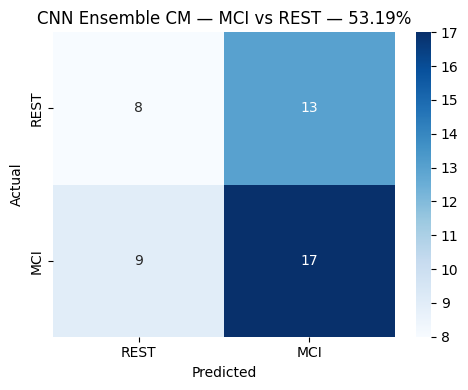

In [10]:
print(f"{'='*65}")
print(f"  WEIGHTED ENSEMBLE — HOLD-OUT TEST EVALUATION (Patient-Level)")
print(f"  Model: CNN (trained from scratch)")
print(f"{'='*65}")

final_results       = {}
pid_to_true_class   = {pid: CLASS_NAMES[l] for p, l, pid in test_entries}
per_patient_records = defaultdict(dict)

for pos_class_idx, pos_name in enumerate(CLASS_NAMES):
    binary_names = ["REST", pos_name]

    test_bin = [
        (p, 1 if l == pos_class_idx else 0, pid)
        for p, l, pid in test_entries
    ]
    test_ds     = SliceDataset(test_bin, augment=False)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                             num_workers=NUM_WORKERS, pin_memory=True)

    fold_accs    = np.array(fold_results[pos_name])
    fold_weights = fold_accs / fold_accs.sum()

    print(f"\n  {pos_name} vs REST")
    for fi, (acc, w) in enumerate(zip(fold_accs, fold_weights)):
        print(f"    Fold {fi+1}: val_acc={acc*100:.2f}%  weight={w:.4f}")

    fold_models = all_fold_models[pos_name]
    for m in fold_models:
        m.to(device); m.eval()

    patient_probs  = defaultdict(lambda: np.zeros(2))
    patient_labels = {}
    with torch.no_grad():
        for images, labels, pids in tqdm(test_loader, desc=f"{pos_name} — Ensemble Eval", leave=False):
            images = images.to(device, non_blocking=True)
            weighted_probs = np.zeros((images.size(0), 2))
            for fm, w in zip(fold_models, fold_weights):
                with torch.amp.autocast(device_type="cuda"):
                    logits = fm(images)
                weighted_probs += w * torch.softmax(logits.float(), dim=1).cpu().numpy()
            for wp, label, pid in zip(weighted_probs, labels.numpy(), pids):
                patient_probs[pid]  += wp
                patient_labels[pid]  = int(label)

    all_true, all_pred = [], []
    for pid, wp_sum in patient_probs.items():
        all_true.append(patient_labels[pid])
        all_pred.append(int(np.argmax(wp_sum)))
        per_patient_records[pid]["true_class"]               = pid_to_true_class[pid]
        per_patient_records[pid][f"{pos_name}_positive_call"] = int(np.argmax(wp_sum))
        per_patient_records[pid][f"{pos_name}_confidence"]    = float(wp_sum[1] / wp_sum.sum())

    pat_acc = np.mean(np.array(all_true) == np.array(all_pred))
    pos_f1  = f1_score(all_true, all_pred, pos_label=1, zero_division=0)

    print(f"\n  Weighted Ensemble Test Acc ({pos_name} vs REST): "
          f"{pat_acc*100:.2f}%  [{len(patient_probs)} patients]")
    print(classification_report(all_true, all_pred, target_names=binary_names, zero_division=0))

    cm = confusion_matrix(all_true, all_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=binary_names, yticklabels=binary_names)
    plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.title(f"CNN Ensemble CM — {pos_name} vs REST — {pat_acc*100:.2f}%")
    plt.tight_layout()
    plt.savefig(os.path.join(CKPT_DIR, f"cm_ensemble_{pos_name}_vs_rest.png"), dpi=150)
    plt.show()

    final_results[pos_name] = {
        "patient_test_acc": pat_acc,
        "positive_f1":      float(pos_f1),
        "cv_mean_acc":      float(np.mean(fold_accs)),
        "cv_std_acc":       float(np.std(fold_accs)),
        "fold_weights":     fold_weights.tolist(),
    }

    for m in fold_models:
        m.to("cpu")
    del test_ds
    torch.cuda.empty_cache()

## 9b — Overall Macro F1 (3-Class, Patient-Level)

  OVERALL MACRO F1 — CNN WEIGHTED ENSEMBLE (47 test patients)
  One-vs-rest positive-class F1: AD=0.4286, CN=0.4762, MCI=0.6071
  One-vs-rest macro F1 : 0.5040
  3-class accuracy     : 59.57%
  3-class macro F1     : 0.5164

              precision    recall  f1-score   support

          AD     0.5714    0.5000    0.5333         8
          CN     0.5000    0.2308    0.3158        13
         MCI     0.6176    0.8077    0.7000        26

    accuracy                         0.5957        47
   macro avg     0.5630    0.5128    0.5164        47
weighted avg     0.5772    0.5957    0.5654        47



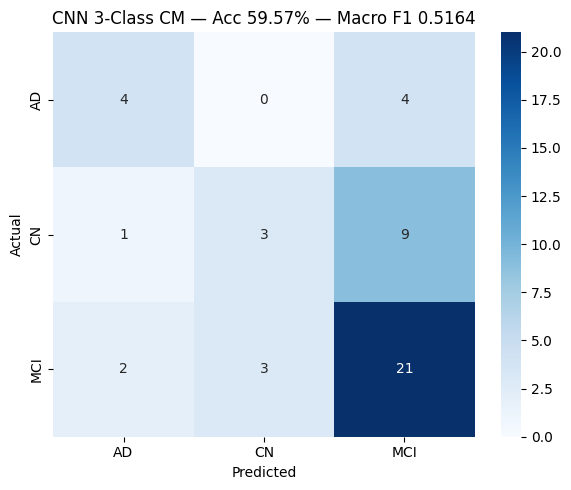

In [11]:
# (a) One-vs-rest macro F1 = mean of each binary model's positive-class F1
ovr_macro_f1 = float(np.mean([final_results[c]["positive_f1"] for c in CLASS_NAMES]))

# (b) True 3-class macro F1: each patient → class whose ensemble is most confident
mc_pids = sorted(per_patient_records)
mc_true = [per_patient_records[p]["true_class"] for p in mc_pids]
mc_pred = [CLASS_NAMES[int(np.argmax([per_patient_records[p][f"{c}_confidence"] for c in CLASS_NAMES]))]
           for p in mc_pids]
for p, pred in zip(mc_pids, mc_pred):
    per_patient_records[p]["pred_class_3way"] = pred

mc_acc      = float(np.mean(np.array(mc_true) == np.array(mc_pred)))
mc_macro_f1 = float(f1_score(mc_true, mc_pred, labels=CLASS_NAMES, average="macro", zero_division=0))

print(f"{'='*65}")
print(f"  OVERALL MACRO F1 — CNN WEIGHTED ENSEMBLE ({len(mc_pids)} test patients)")
print(f"{'='*65}")
print("  One-vs-rest positive-class F1: " +
      ", ".join(f"{c}={final_results[c]['positive_f1']:.4f}" for c in CLASS_NAMES))
print(f"  One-vs-rest macro F1 : {ovr_macro_f1:.4f}")
print(f"  3-class accuracy     : {mc_acc*100:.2f}%")
print(f"  3-class macro F1     : {mc_macro_f1:.4f}\n")
print(classification_report(mc_true, mc_pred, labels=CLASS_NAMES, digits=4, zero_division=0))

cm3 = confusion_matrix(mc_true, mc_pred, labels=CLASS_NAMES)
plt.figure(figsize=(6, 5))
sns.heatmap(cm3, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"CNN 3-Class CM — Acc {mc_acc*100:.2f}% — Macro F1 {mc_macro_f1:.4f}")
plt.tight_layout()
plt.savefig(os.path.join(CKPT_DIR, "cm_3class.png"), dpi=150)
plt.show()

## 10 — Summary & Save Results

In [12]:
print(f"\n{'='*65}")
print(f"  FINAL SUMMARY — CNN WEIGHTED ENSEMBLE")
print(f"{'='*65}")
print(f"  {'Class':<8} {'CV Acc (mean±std)':<24} {'Test Acc':<12} {'Test F1 (pos)'}")
print(f"  {'-'*65}")

for cls, res in final_results.items():
    cv_str   = f"{res['cv_mean_acc']*100:.2f}% ± {res['cv_std_acc']*100:.2f}%"
    test_str = f"{res['patient_test_acc']*100:.2f}%"
    print(f"  {cls:<8} {cv_str:<24} {test_str:<12} {res['positive_f1']:.4f}")
print(f"\n  One-vs-rest macro F1: {ovr_macro_f1:.4f}   |   3-class macro F1: {mc_macro_f1:.4f}"
      f"   |   3-class acc: {mc_acc*100:.2f}%")

csv_path = os.path.join(CKPT_DIR, "results_cnn_weighted_ensemble.csv")
with open(csv_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=[
        "class", "cv_mean_acc_%", "cv_std_%", "ensemble_test_acc_%", "test_positive_f1", "fold_weights"
    ])
    writer.writeheader()
    for cls, res in final_results.items():
        writer.writerow({
            "class":               cls,
            "cv_mean_acc_%":       round(res["cv_mean_acc"] * 100, 2),
            "cv_std_%":            round(res["cv_std_acc"]  * 100, 2),
            "ensemble_test_acc_%": round(res["patient_test_acc"] * 100, 2),
            "test_positive_f1":    round(res["positive_f1"], 4),
            "fold_weights":        str([round(w, 4) for w in res["fold_weights"]]),
        })
    writer.writerow({"class": "OVERALL_ovr_macro_f1", "test_positive_f1": round(ovr_macro_f1, 4)})
    writer.writerow({"class": "OVERALL_3class", "ensemble_test_acc_%": round(mc_acc * 100, 2),
                     "test_positive_f1": round(mc_macro_f1, 4)})
print(f"\n  Results saved -> {csv_path}")

pp_csv_path = os.path.join(CKPT_DIR, "per_patient_cnn_predictions.csv")
fieldnames  = (["patient_id", "true_class", "pred_class_3way"] +
               [f"{c}_{k}" for c in CLASS_NAMES for k in ("positive_call", "confidence")])
with open(pp_csv_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    for pid, rec in per_patient_records.items():
        writer.writerow({"patient_id": pid, **{k: rec.get(k) for k in fieldnames[1:]}})
print(f"  Per-patient predictions saved -> {pp_csv_path}")


  FINAL SUMMARY — CNN WEIGHTED ENSEMBLE
  Class    CV Acc (mean±std)        Test Acc     Test F1 (pos)
  -----------------------------------------------------------------
  AD       79.15% ± 3.43%           82.98%       0.4286
  CN       71.44% ± 1.56%           76.60%       0.4762
  MCI      54.98% ± 3.07%           53.19%       0.6071

  One-vs-rest macro F1: 0.5040   |   3-class macro F1: 0.5164   |   3-class acc: 59.57%

  Results saved -> /kaggle/working/checkpoints_cnn/results_cnn_weighted_ensemble.csv
  Per-patient predictions saved -> /kaggle/working/checkpoints_cnn/per_patient_cnn_predictions.csv


In [13]:
torch.save({cls: [m.state_dict() for m in all_fold_models[cls]] for cls in CLASS_NAMES},
           os.path.join(CKPT_DIR, "all_cnn_fold_models.pt"))
print(f"All CNN fold models saved to: {os.path.join(CKPT_DIR, 'all_cnn_fold_models.pt')}")

All CNN fold models saved to: /kaggle/working/checkpoints_cnn/all_cnn_fold_models.pt


## XAI Techniques

Each class uses the fold-1 model of its own "class vs REST" ensemble; target index 1 = the positive class.

In [14]:
!pip install -q grad-cam lime shap

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [15]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import cv2

from lime import lime_image
from skimage.segmentation import mark_boundaries

import shap

xai_models = {cls: all_fold_models[cls][0].to(device).eval() for cls in CLASS_NAMES}

def load_slice(path):
    """Same preprocessing as training: grayscale → 224 → 3-channel → ImageNet normalize."""
    img_pil    = Image.open(path).convert("L").resize((IMAGE_SIZE, IMAGE_SIZE))
    img_rgb    = np.stack([np.array(img_pil)] * 3, axis=-1).astype(np.float32) / 255.0
    img_tensor = normalize(transforms.ToTensor()(img_pil).repeat(3, 1, 1))
    return img_pil, img_rgb, img_tensor

### Grad-CAM

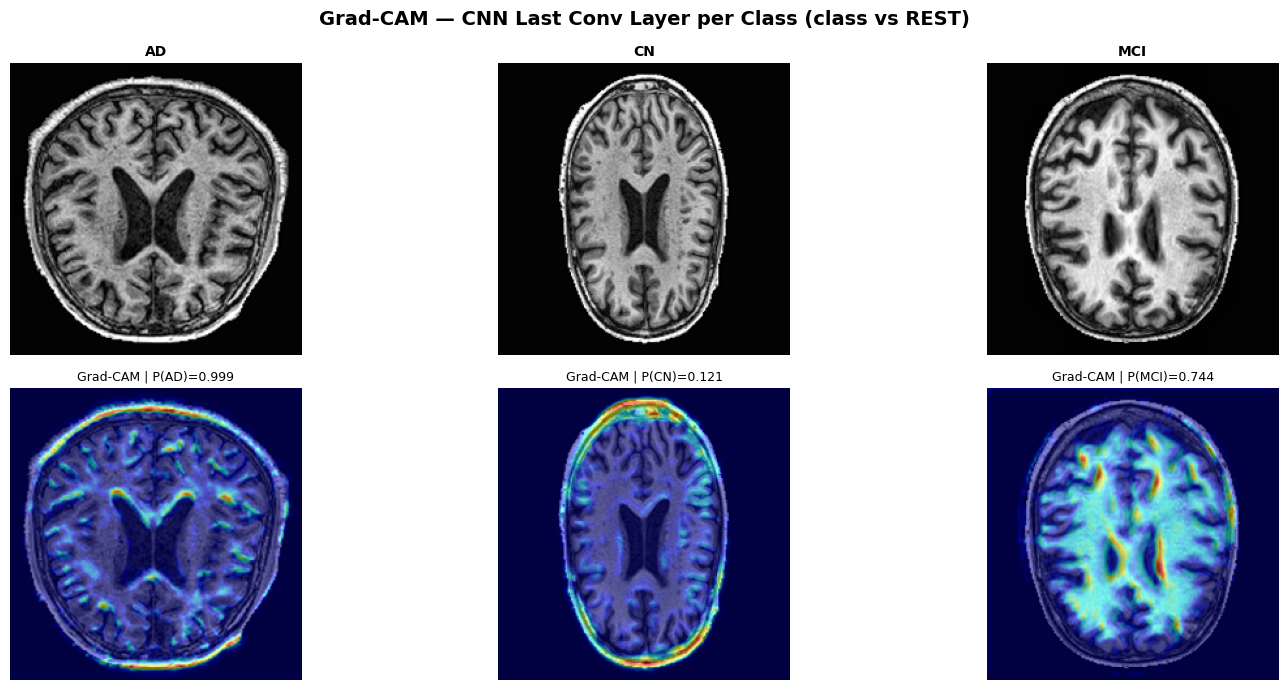

In [16]:
fig, axes = plt.subplots(2, len(CLASS_NAMES), figsize=(16, 7))
fig.suptitle("Grad-CAM — CNN Last Conv Layer per Class (class vs REST)", fontsize=14, fontweight='bold')

for idx, (cls_name, label) in enumerate(zip(CLASS_NAMES, range(len(CLASS_NAMES)))):
    model_gc = xai_models[cls_name]
    for p in model_gc.parameters():
        p.requires_grad = True
    target_layer = [[m for m in model_gc.modules() if isinstance(m, nn.Conv2d)][-1]]
    cam = GradCAM(model=model_gc, target_layers=target_layer)

    sample_entry = next((e for e in test_entries if e[1] == label), None)
    if sample_entry is None:
        print(f"[WARNING] No test slice found for class {cls_name}")
        continue

    path, lbl, pid = sample_entry
    img_pil, img_np_display, img_tensor = load_slice(path)
    input_tensor = img_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        prob_pos = torch.softmax(model_gc(input_tensor), dim=1)[0, 1].item()

    grayscale_cam = cam(input_tensor=input_tensor, targets=[ClassifierOutputTarget(1)])[0]
    cam_image     = show_cam_on_image(img_np_display, grayscale_cam, use_rgb=True)

    axes[0][idx].imshow(img_np_display)
    axes[0][idx].set_title(cls_name, fontsize=10, fontweight='bold')
    axes[0][idx].axis('off')

    axes[1][idx].imshow(cam_image)
    axes[1][idx].set_title(f'Grad-CAM | P({cls_name})={prob_pos:.3f}', fontsize=9)
    axes[1][idx].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(CKPT_DIR, "cnn_gradcam.png"), dpi=150)
plt.show()

### LIME

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

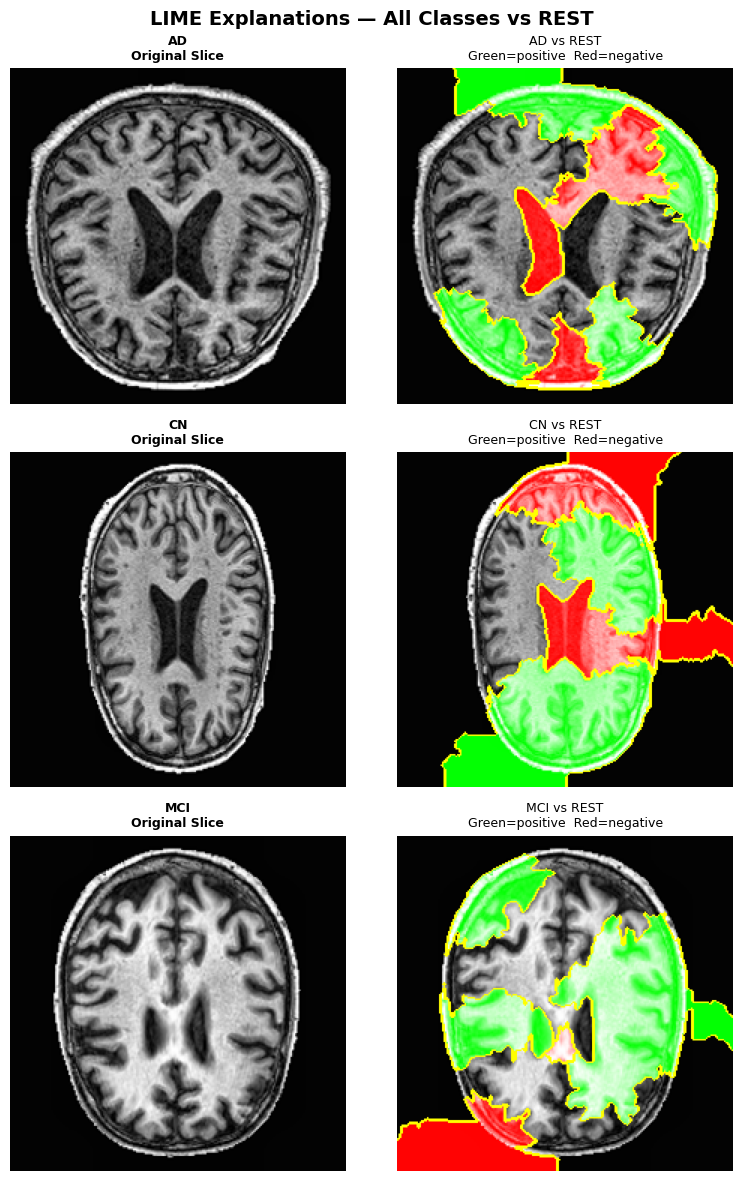

In [17]:
fig, axes = plt.subplots(len(CLASS_NAMES), 2, figsize=(8, len(CLASS_NAMES) * 4))
fig.suptitle("LIME Explanations — All Classes vs REST", fontsize=14, fontweight='bold')

for idx, (pos_name_lime, pos_class_idx) in enumerate(zip(CLASS_NAMES, range(len(CLASS_NAMES)))):

    model_lime = xai_models[pos_name_lime]

    def lime_predict_fn(images_np):
        batch = []
        for img in images_np:
            pil = Image.fromarray(img).convert("L").resize((IMAGE_SIZE, IMAGE_SIZE))
            batch.append(normalize(transforms.ToTensor()(pil).repeat(3, 1, 1)))
        batch_tensor = torch.stack(batch).to(device)
        with torch.no_grad():
            return torch.softmax(model_lime(batch_tensor), dim=1).cpu().numpy()

    sample_entry = next((e for e in test_entries if e[1] == pos_class_idx), None)
    if sample_entry is None:
        print(f"[WARNING] No test slice for {pos_name_lime}")
        continue

    path, lbl, pid = sample_entry
    _, img_rgb_l, _ = load_slice(path)
    img_uint8 = (img_rgb_l * 255).astype(np.uint8)

    explainer_lime = lime_image.LimeImageExplainer(random_state=SEED)
    explanation    = explainer_lime.explain_instance(
        img_uint8,
        lime_predict_fn,
        top_labels=2,
        hide_color=0,
        num_samples=500,
        random_seed=SEED,
    )

    lime_img, mask = explanation.get_image_and_mask(
        label=1,
        positive_only=False,
        num_features=10,
        hide_rest=False,
    )

    axes[idx][0].imshow(img_uint8)
    axes[idx][0].set_title(f"{pos_name_lime}\nOriginal Slice", fontsize=9, fontweight='bold')
    axes[idx][0].axis('off')

    axes[idx][1].imshow(mark_boundaries(lime_img, mask))
    axes[idx][1].set_title(f"{pos_name_lime} vs REST\nGreen=positive  Red=negative", fontsize=9)
    axes[idx][1].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(CKPT_DIR, "xai_lime_all_classes.png"), dpi=150)
plt.show()

### SHAP

The CNN is trained end-to-end on pixels, so SHAP explains input pixels (GradientExplainer) rather than the 512 AlexNet features used in the AlexNet+SVM notebook.


  SHAP — AD vs REST

  SHAP — CN vs REST

  SHAP — MCI vs REST


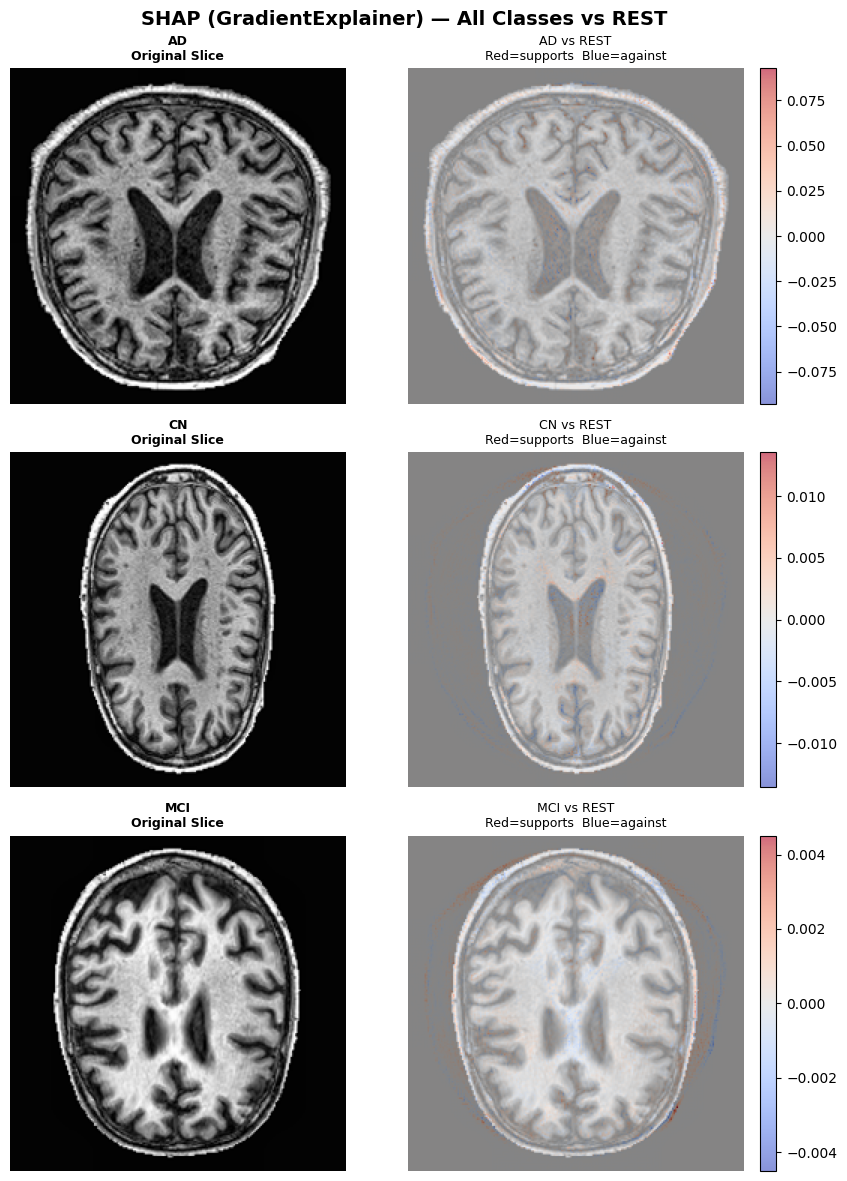

In [18]:
fig, axes = plt.subplots(len(CLASS_NAMES), 2, figsize=(9, len(CLASS_NAMES) * 4))
fig.suptitle("SHAP (GradientExplainer) — All Classes vs REST", fontsize=14, fontweight='bold')

for idx, (pos_name_shap, pos_class_idx) in enumerate(zip(CLASS_NAMES, range(len(CLASS_NAMES)))):

    print(f"\n  SHAP — {pos_name_shap} vs REST")
    model_shap = xai_models[pos_name_shap]

    bg_entries = (
        [e for e in test_entries if e[1] == pos_class_idx][:25] +
        [e for e in test_entries if e[1] != pos_class_idx][:25])
    bg = torch.stack([load_slice(p)[2] for p, _, _ in bg_entries]).to(device)

    sample_entry = next((e for e in test_entries if e[1] == pos_class_idx), None)
    if sample_entry is None:
        print(f"  [WARNING] No test slices for {pos_name_shap}, skipping.")
        continue
    path, lbl, pid = sample_entry
    _, img_rgb, img_tensor = load_slice(path)
    x = img_tensor.unsqueeze(0).to(device)

    explainer   = shap.GradientExplainer(model_shap, bg)
    shap_values = explainer.shap_values(x)

    sv = np.asarray(shap_values[1] if isinstance(shap_values, list) else shap_values)
    sv = sv[0]                                      # drop batch dim
    if sv.ndim == 4:                                # (C, H, W, n_outputs) in newer shap
        sv = sv[..., 1]
    imp  = sv.sum(axis=0)                           # sum over channels → (H, W)
    vmax = np.abs(imp).max() + 1e-8

    axes[idx][0].imshow(img_rgb)
    axes[idx][0].set_title(f"{pos_name_shap}\nOriginal Slice", fontsize=9, fontweight='bold')
    axes[idx][0].axis('off')

    axes[idx][1].imshow(img_rgb)
    im = axes[idx][1].imshow(imp, cmap="coolwarm", alpha=0.6, vmin=-vmax, vmax=vmax)
    axes[idx][1].set_title(f"{pos_name_shap} vs REST\nRed=supports  Blue=against", fontsize=9)
    axes[idx][1].axis('off')
    plt.colorbar(im, ax=axes[idx][1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(os.path.join(CKPT_DIR, "xai_shap_all_classes.png"), dpi=150)
plt.show()

### Occlusion Sensitivity

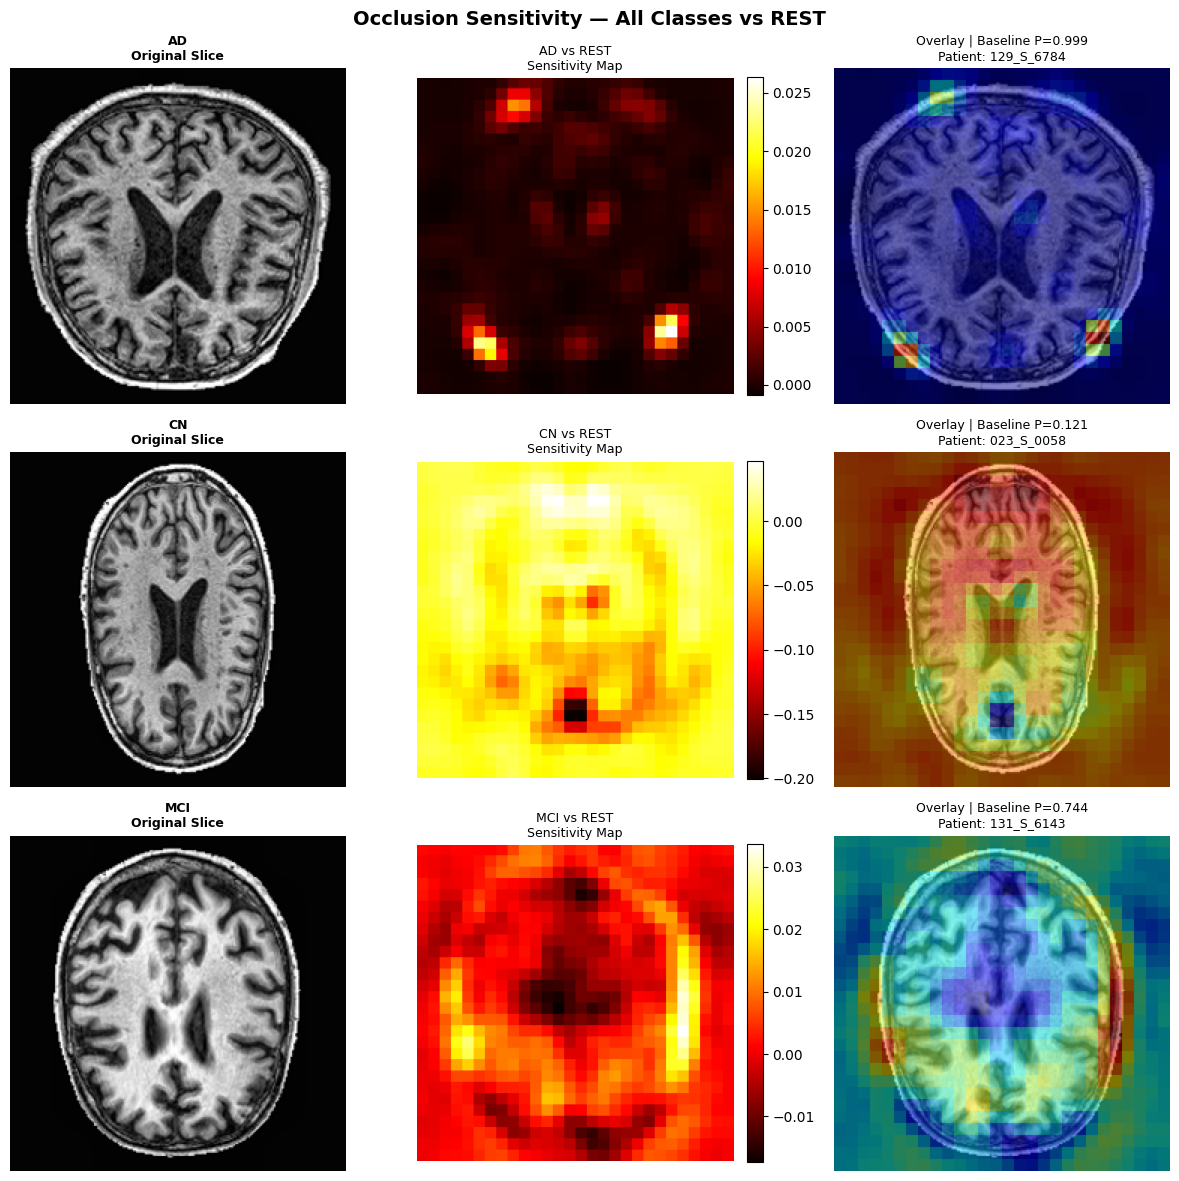

In [19]:
def occlusion_sensitivity(image_tensor, model, patch_size=16, stride=8, occlude_value=0.0):
    C, H, W  = image_tensor.shape
    sens_map = np.zeros((H, W), dtype=np.float32)
    count    = np.zeros((H, W), dtype=np.float32)

    model.eval()
    with torch.no_grad():
        base_prob = torch.softmax(model(image_tensor.unsqueeze(0).to(device)), dim=1)[0, 1].item()

        for y in range(0, H - patch_size + 1, stride):
            for x in range(0, W - patch_size + 1, stride):
                occluded = image_tensor.clone()
                occluded[:, y:y+patch_size, x:x+patch_size] = occlude_value
                occ_prob = torch.softmax(model(occluded.unsqueeze(0).to(device)), dim=1)[0, 1].item()
                drop = base_prob - occ_prob
                sens_map[y:y+patch_size, x:x+patch_size] += drop
                count   [y:y+patch_size, x:x+patch_size] += 1

    sens_map /= np.maximum(count, 1)
    return sens_map, base_prob

fig, axes = plt.subplots(len(CLASS_NAMES), 3, figsize=(12, len(CLASS_NAMES) * 4))
fig.suptitle("Occlusion Sensitivity — All Classes vs REST", fontsize=14, fontweight='bold')

for idx, (pos_name_occ, pos_class_idx) in enumerate(zip(CLASS_NAMES, range(len(CLASS_NAMES)))):

    model_occ = xai_models[pos_name_occ]

    sample_entry = next((e for e in test_entries if e[1] == pos_class_idx), None)
    if sample_entry is None:
        print(f"[WARNING] No test slice for {pos_name_occ}, skipping.")
        continue

    path, lbl, pid = sample_entry
    _, img_rgb, img_tensor = load_slice(path)

    sens_map, base_prob = occlusion_sensitivity(img_tensor, model_occ, patch_size=16, stride=8)
    sens_norm = (sens_map - sens_map.min()) / (sens_map.max() - sens_map.min() + 1e-8)

    axes[idx][0].imshow(img_rgb)
    axes[idx][0].set_title(f"{pos_name_occ}\nOriginal Slice", fontsize=9, fontweight='bold')
    axes[idx][0].axis('off')

    im = axes[idx][1].imshow(sens_map, cmap="hot")
    axes[idx][1].set_title(f"{pos_name_occ} vs REST\nSensitivity Map", fontsize=9)
    axes[idx][1].axis('off')
    plt.colorbar(im, ax=axes[idx][1], fraction=0.046, pad=0.04)

    axes[idx][2].imshow(img_rgb)
    axes[idx][2].imshow(sens_norm, cmap="jet", alpha=0.5)
    axes[idx][2].set_title(f"Overlay | Baseline P={base_prob:.3f}\nPatient: {pid}", fontsize=9)
    axes[idx][2].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(CKPT_DIR, "cnn_occlusion.png"), dpi=150)
plt.show()